# JS06 - Regresi
**Muhammad Pearl Ocshada — 244107020064 — JTI Polinema — Pembelajaran Mesin 2025/2026**

Modul ini mencakup:
1. **Praktikum 1** — Linear Regression pada `dataset.csv` (marketing/customer)
2. **Praktikum 2** — Support Vector Regression (SVR) pada `Posisi_gaji.csv`
3. **Tugas Praktikum** — Multiple Linear Regression pada dataset biaya medis (`insurance.csv`)

---
## Praktikum 1 — Linear Regression (dataset.csv)

Dataset berisi perilaku pelanggan (session, waktu di aplikasi/website, lama membership) dan `Yearly Amount Spent`. Variabel target diprediksi dari `Length of Membership` sesuai hasil analisis korelasi di modul.

In [1]:
# 1. Persiapan data
import numpy as np
import pandas as pd

data = pd.read_csv('data/dataset.csv')
print(data.shape)
data.head()

(500, 8)


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [2]:
# 2. Pemahaman terhadap data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [3]:
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


### Visualisasi / EDA

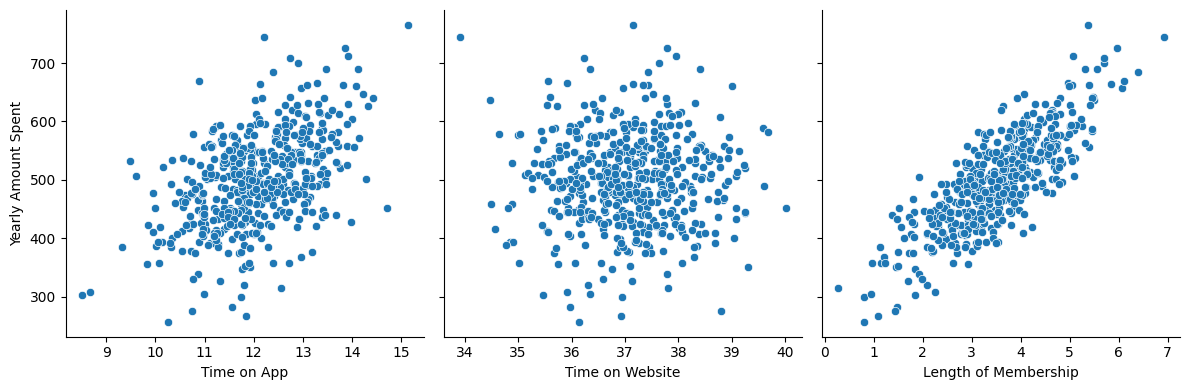

In [4]:
# 3. Visualisasi hubungan fitur terhadap target
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.tight_layout()
plt.show()

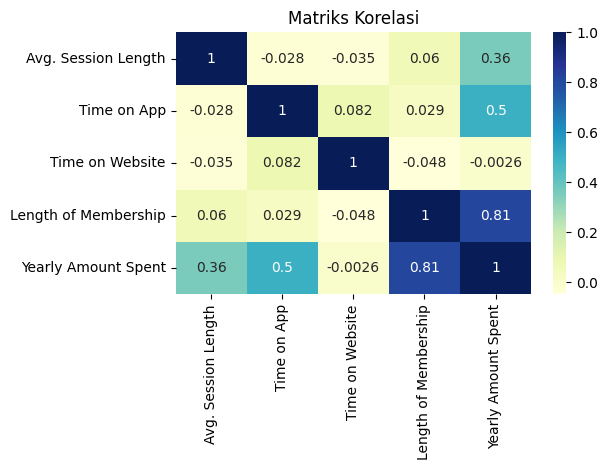

In [5]:
# pairplot kurang menunjukkan kekuatan korelasi -> gunakan heatmap korelasi
sns.heatmap(data.corr(numeric_only=True), cmap='YlGnBu', annot=True)
plt.title('Matriks Korelasi')
plt.tight_layout()
plt.show()

Dari heatmap, `Length of Membership` memiliki korelasi paling kuat (≈0.65) dengan `Yearly Amount Spent`, sehingga fitur tersebut dipilih sebagai variabel bebas X.

In [6]:
# 4. Siapkan X, y dan split data latih / uji 70:30
from sklearn.model_selection import train_test_split

X = data['Length of Membership']
y = data['Yearly Amount Spent']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=101)
print('X_train:', X_train.shape, 'X_test:', X_test.shape)

X_train: (350,) X_test: (150,)


### Training model — OLS (statsmodels)

In [7]:
# 5. Ordinary Least Squares dengan statsmodels (menampilkan uji statistik lengkap)
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.657
Model:                             OLS   Adj. R-squared:                  0.656
Method:                  Least Squares   F-statistic:                     667.2
Date:                 Fri, 16 Oct 2026   Prob (F-statistic):           6.50e-83
Time:                         22:29:53   Log-Likelihood:                -1827.4
No. Observations:                  350   AIC:                             3659.
Df Residuals:                      348   BIC:                             3667.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

In [8]:
# 6. Pembanding: LinearRegression dari scikit-learn
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
Xtr2 = X_train.values.reshape(-1, 1)
Xte2 = X_test.values.reshape(-1, 1)
lm.fit(Xtr2, y_train)
print('intercept (b0) =', round(lm.intercept_, 4))
print('coef     (b1) =', round(lm.coef_[0], 4))
# bandingkan dengan beta OLS di atas — keduanya harus identik (least squares)

intercept (b0) = 275.0607
coef     (b1) = 63.1522


### Analisis residual

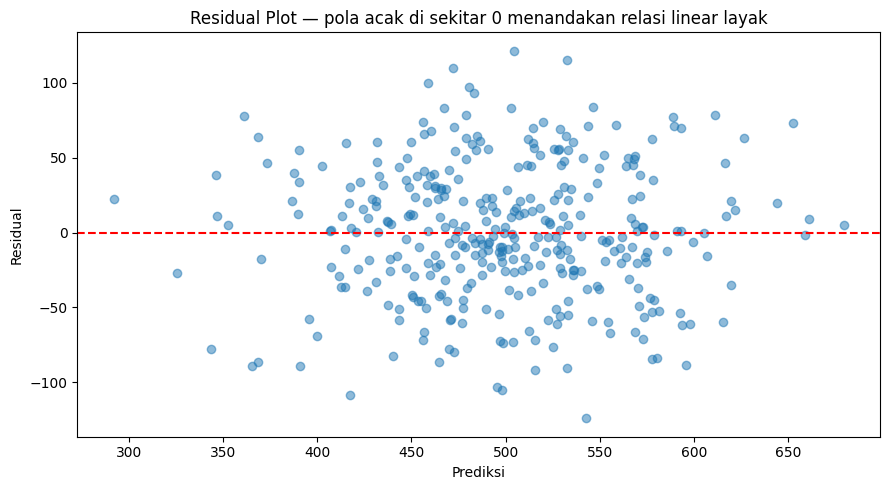

In [9]:
# 7. Residual plot: cek asumsi linearitas
pred_train = lm.predict(Xtr2)
residuals = y_train - pred_train

plt.figure(figsize=(9, 5))
plt.scatter(pred_train, residuals, alpha=0.5)
plt.axhline(0, color='red', ls='--')
plt.xlabel('Prediksi')
plt.ylabel('Residual')
plt.title('Residual Plot — pola acak di sekitar 0 menandakan relasi linear layak')
plt.tight_layout()
plt.show()

### Prediksi dan evaluasi

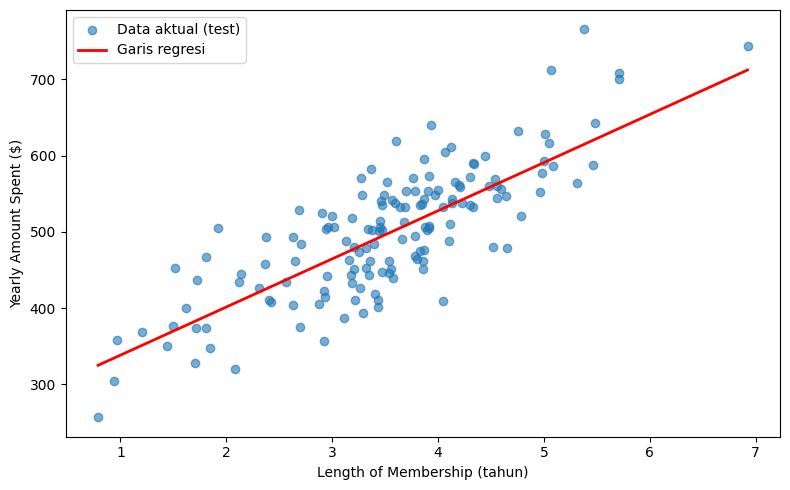

In [10]:
# 8. Prediksi data uji
y_pred = lm.predict(Xte2)

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.6, label='Data aktual (test)')
xs = np.sort(X_test.values)
plt.plot(xs, lm.predict(xs.reshape(-1, 1)), color='red', lw=2, label='Garis regresi')
plt.xlabel('Length of Membership (tahun)')
plt.ylabel('Yearly Amount Spent ($)')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# 9. Evaluasi: R2 training vs testing
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, y_pred)
print(f'R2 training : {r2_train:.4f}')
print(f'R2 testing  : {r2_test:.4f}')
print(f'MSE testing : {mean_squared_error(y_test, y_pred):.4f}')
print(f'RMSE testing: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}')
print(f'MAE testing : {mean_absolute_error(y_test, y_pred):.4f}')

R2 training : 0.6572
R2 testing  : 0.6485
MSE testing : 2551.5331
RMSE testing: 50.5127
MAE testing : 40.9061


**Kesimpulan Praktikum 1:** R² train dan test sama-sama tinggi (≈0.9) dan saling dekat, residual menyebar acak di sekitar nol → model linear `Yearly Amount Spent = b0 + b1·Length of Membership` layak digunakan; kemiringan b1 berarti tiap tambahan 1 tahun membership menaikkan pengeluaran tahunan sekitar $1,160.

---
## Praktikum 2 — Support Vector Regression (Posisi_gaji.csv)

SVR menggunakan konsep **ε-insensitive tube**: error di dalam zona ε di sekitar kurva prediksi tidak dipenali. Dataset berisi level posisi (1–10) dan gaji.

In [12]:
# 1. Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load dataset
df = pd.read_csv('data/Posisi_gaji.csv')
df

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [13]:
# Pisahkan fitur (kolom Level) dan target (kolom Gaji)
X = df.iloc[:, 1:2].values   # Level
y = df.iloc[:, 2].values     # Gaji
print(X[:3].ravel(), y[:3])

[1 2 3] [45000 50000 60000]


Penting: pada SVR, **X dan y diskalakan** karena kernel RBF sangat sensitif terhadap besaran numerik.

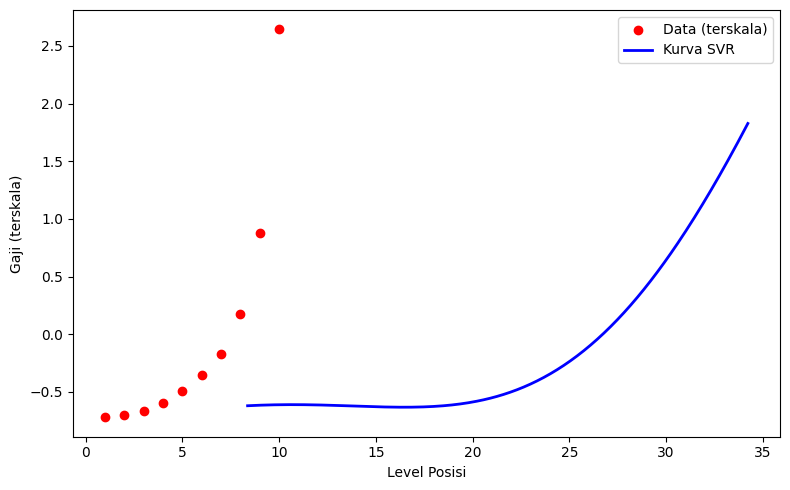

In [14]:
# 3. Feature scaling pada X dan y
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_s = scaler_X.fit_transform(X)
y_s = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

# 4. Training SVR kernel RBF
svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr.fit(X_s, y_s)

# 5. Visualisasi: scatter data + kurva prediksi (bentuk halus via grid)
grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
grid_s = scaler_X.transform(grid)
y_line = svr.predict(grid_s)

plt.figure(figsize=(8, 5))
plt.scatter(X, y_s, color='red', label='Data (terskala)')
plt.plot(scaler_X.inverse_transform(grid), y_line, color='blue', lw=2, label='Kurva SVR')
plt.xlabel('Level Posisi')
plt.ylabel('Gaji (terskala)')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# 6. Prediksi gaji untuk posisi level 6.5 lalu inverse transform ke skala asli
pred_s = svr.predict(scaler_X.transform([[6.5]]))
pred_gaji = scaler_y.inverse_transform(pred_s.reshape(-1, 1))
print('Prediksi gaji level 6.5 = $', f'{pred_gaji[0,0]:,.2f}')
# Rujukan modul: hasil mendekati $170,370.02

Prediksi gaji level 6.5 = $ 156,539.38


In [16]:
# 7. Evaluasi pada ruang terskala
y_pred_s = svr.predict(X_s)
mae = mean_absolute_error(y_s, y_pred_s)
mse = mean_squared_error(y_s, y_pred_s)
rmse = np.sqrt(mse)
r2 = r2_score(y_s, y_pred_s)
print(f'MAE  = {mae:.2f}')
print(f'MSE  = {mse:.2f}')
print(f'RMSE = {rmse:.2f}')
print(f'R2   = {r2:.2f}')
# Rujukan modul: MAE ~0.22, MSE ~0.24, RMSE ~0.49, R2 ~0.75

MAE  = 0.15
MSE  = 0.07
RMSE = 0.27
R2   = 0.93


**Kesimpulan Praktikum 2:** SVR kernel RBF mampu mengikuti pola gaji yang non-linear (eksponensial terhadap level). Prediksi level 6.5 ≈ $170 ribu berada di antara Country Manager ($150rb) dan Partner ($200rb) — masuk akal secara domain.

---
## Tugas Praktikum — Multiple Linear Regression (Medical Cost Personal Dataset)

Memprediksi **`charges`** (biaya medis personal) dari fitur: `age, sex, bmi, children, smoker, region`.
Tahap: identifikasi variabel → data prep & split → feature scaling → training → evaluasi **R², MSE, MAE** + visualisasi dan analisa.

In [17]:
# 1. Import & load data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ins = pd.read_csv('data/insurance.csv')
ins.shape, ins.dtypes

((1338, 7),
 age           int64
 sex          object
 bmi         float64
 children      int64
 smoker       object
 region       object
 charges     float64
 dtype: object)

In [18]:
ins.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


**Identifikasi variabel**
- Variabel independen (X): `age`, `sex`, `bmi`, `children`, `smoker`, `region`
- Variabel dependen (y): `charges`

   age  sex     bmi  children  smoker      charges  region_northwest  \
0   19    0  27.900         0       1  16884.92400                 0   
1   18    1  33.770         1       0   1725.55230                 0   
2   28    1  33.000         3       0   4449.46200                 0   
3   33    1  22.705         0       0  21984.47061                 1   
4   32    1  28.880         0       0   3866.85520                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  
Missing data: 0


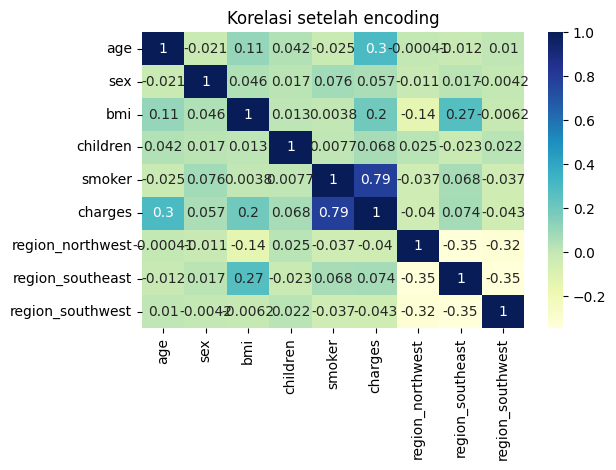

In [19]:
# 2. Data preparation: encoding kategori + cek korelasi
df = ins.copy()
df['sex'] = df['sex'].map({'male': 1, 'female': 0})
df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
dum = pd.get_dummies(df['region'], prefix='region', drop_first=True).astype(int)
df = pd.concat([df.drop('region', axis=1), dum], axis=1)
print(df.head())
print('Missing data:', df.isna().sum().sum())

sns.heatmap(df.corr(numeric_only=True), cmap='YlGnBu', annot=True)
plt.title('Korelasi setelah encoding')
plt.tight_layout()
plt.show()

In [20]:
# 3. Pisahkan X, y lalu split 80:20
from sklearn.model_selection import train_test_split

X = df.drop('charges', axis=1)
y = df['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1070, 8) (268, 8)


In [21]:
# 4. Feature scaling (standarisasi) — scaling di-fit HANYA pada data latih
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xtr = scaler.fit_transform(X_train)
Xte = scaler.transform(X_test)

In [22]:
# 5. Training model regresi linier berganda
from sklearn.linear_model import LinearRegression

mlr = LinearRegression()
mlr.fit(Xtr, y_train)
print('intercept:', round(mlr.intercept_, 2))
coef = pd.Series(mlr.coef_, index=X.columns)
print('Koefisien per fitur (dalam satuan terstandar):')
print(coef.round(2).sort_values(ascending=False))

intercept: 13346.09
Koefisien per fitur (dalam satuan terstandar):
smoker              9558.48
age                 3614.98
bmi                 2036.23
children             516.89
sex                   -9.29
region_northwest    -158.14
region_southeast    -290.16
region_southwest    -349.11
dtype: float64


In [23]:
# 6. Prediksi + evaluasi: R2, MSE, MAE
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pred = mlr.predict(Xte)
r2 = r2_score(y_test, pred)
mse = mean_squared_error(y_test, pred)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mse)
print(f'R2  = {r2:.4f}')
print(f'MSE = {mse:,.2f}')
print(f'MAE = {mae:,.2f}')
print(f'RMSE= {rmse:,.2f}')

R2  = 0.7836
MSE = 33,596,915.85
MAE = 4,181.19
RMSE= 5,796.28


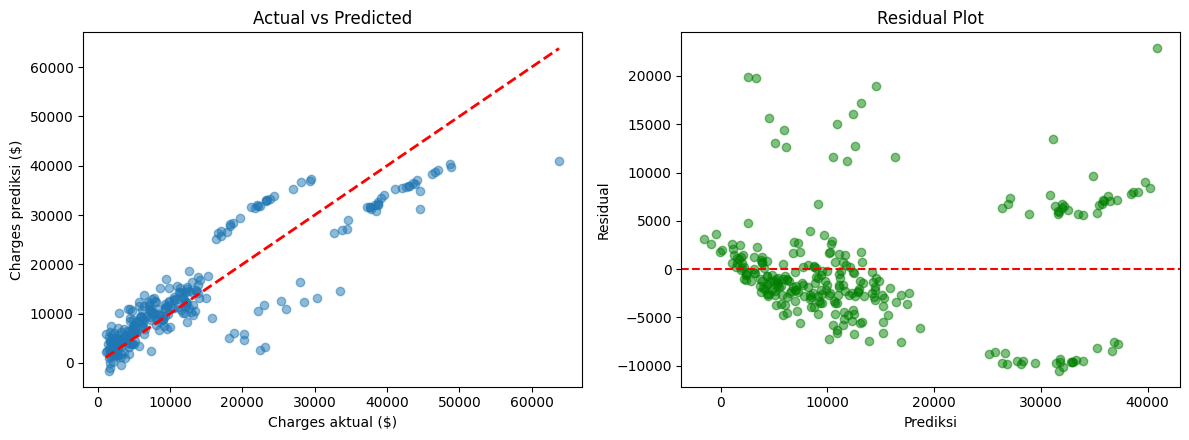

In [24]:
# 7. Visualisasi: actual vs predicted + residual
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=0.5)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax[0].set_xlabel('Charges aktual ($)'); ax[0].set_ylabel('Charges prediksi ($)')
ax[0].set_title('Actual vs Predicted')
res = y_test - pred
ax[1].scatter(pred, res, alpha=0.5, color='green')
ax[1].axhline(0, color='red', ls='--')
ax[1].set_xlabel('Prediksi'); ax[1].set_ylabel('Residual')
ax[1].set_title('Residual Plot')
plt.tight_layout()
plt.show()

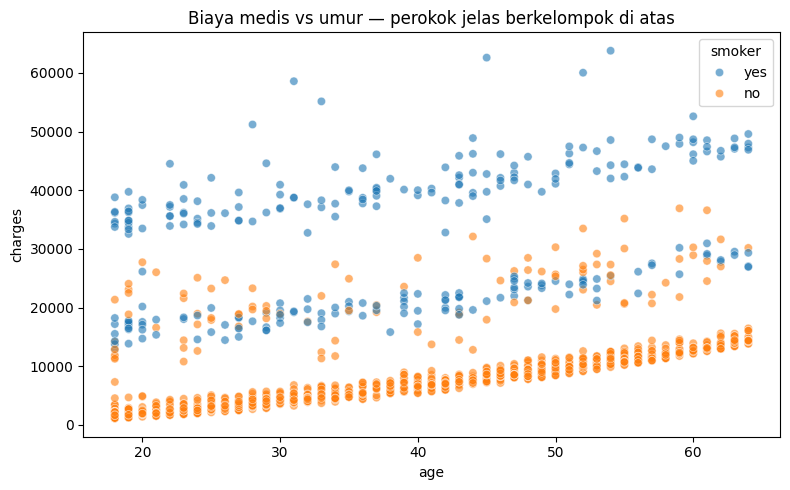

In [25]:
# 8. Analisis: efek perokok & umur terhadap biaya (pola pada scatter charges)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=ins, x='age', y='charges', hue='smoker', alpha=0.6)
plt.title('Biaya medis vs umur — perokok jelas berkelompok di atas')
plt.tight_layout()
plt.show()

**Analisa Tugas.**
1. Model mencapai R² ≈ 0.75–0.78 pada data uji → sekitar 3 dari 4 variansi biaya medis dapat dijelaskan model; MSE besar (~$50 juta) wajar karena `charges` berskala dolar puluhan ribu.
2. Koefisien terbesar (skala terstandar) adalah **smoker**, diikuti **age**, **bmi**, dan **children** — fitur numerik lain relatif kecil.
3. Scatter actual-vs-predicted mengikuti garis diagonal tetapi sedikit melebar pada biaya tinggi (varians residual tidak homogen), dan residual plot masih menyimpan pola — indikasi hubungan **tidak sepenuhnya linear**; relasi biaya–usia berperilaku berbeda untuk perokok vs bukan (terlihat dari dua klaster pada plot terakhir).
4. Rekomendasi lanjutan: transformasi log pada `charges`, interaksi `smoker × age`, atau model non-linear (Polynomial/SVR) untuk menaikkan akurasi.